In [1]:
from ObjaverseDataset import ObjaverseDataset
from torch.utils.data import DataLoader
from pathlib import Path
from utils import *

[transformers] Disabling PyTorch because PyTorch >= 2.4 is required but found 2.2.2
[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [2]:
objaverse_dataset = ObjaverseDataset(category="duck", limit=3)
objaverse_dataloader = DataLoader(objaverse_dataset, batch_size=1, shuffle=False, collate_fn=objaverse_dataset.collate_fn)

dict_keys(['Band_Aid', 'Bible', 'CD_player', 'Christmas_tree', 'Dixie_cup', 'Ferris_wheel', 'Lego', 'Rollerblade', 'Sharpie', 'Tabasco_sauce', 'aerosol_can', 'air_conditioner', 'airplane', 'alarm_clock', 'alcohol', 'alligator', 'almond', 'ambulance', 'amplifier', 'anklet', 'antenna', 'apple', 'apricot', 'apron', 'aquarium', 'arctic_(type_of_shoe)', 'armband', 'armchair', 'armoire', 'armor', 'army_tank', 'artichoke', 'ashtray', 'asparagus', 'atomizer', 'automatic_washer', 'avocado', 'award', 'awning', 'ax', 'baboon', 'baby_buggy', 'backpack', 'bagel', 'baguet', 'bait', 'ball', 'ballet_skirt', 'balloon', 'bamboo', 'banana', 'bandage', 'bandanna', 'banjo', 'banner', 'barbell', 'barge', 'barrel', 'barrow', 'baseball', 'baseball_bat', 'baseball_cap', 'baseball_glove', 'basket', 'basketball', 'basketball_backboard', 'bass_horn', 'bat_(animal)', 'bath_mat', 'bath_towel', 'bathrobe', 'bathtub', 'battery', 'beachball', 'bead', 'beanbag', 'beanie', 'bear', 'bed', 'bedpan', 'bedspread', 'beef_(fo

In [3]:
import utils
import importlib


importlib.reload(utils)

<module 'utils' from '/Users/viktorlynok/PycharmProjects/vlm-based-3d-shape-editing/utils.py'>

=== Processing UID: b5c9d06f19be4c92a1708515f6655573 ===
FEngine (64 bits) created at 0x337868c00 (threading is enabled)
FEngine resolved backend: Metal
Selected physical device 'Apple M4'
Supported GPU families: 
  MTLGPUFamilyCommon3
  MTLGPUFamilyApple7
  MTLGPUFamilyMac2
Features:
  readWriteTextureSupport: true
Backend feature level: 3
FEngine feature level: 1


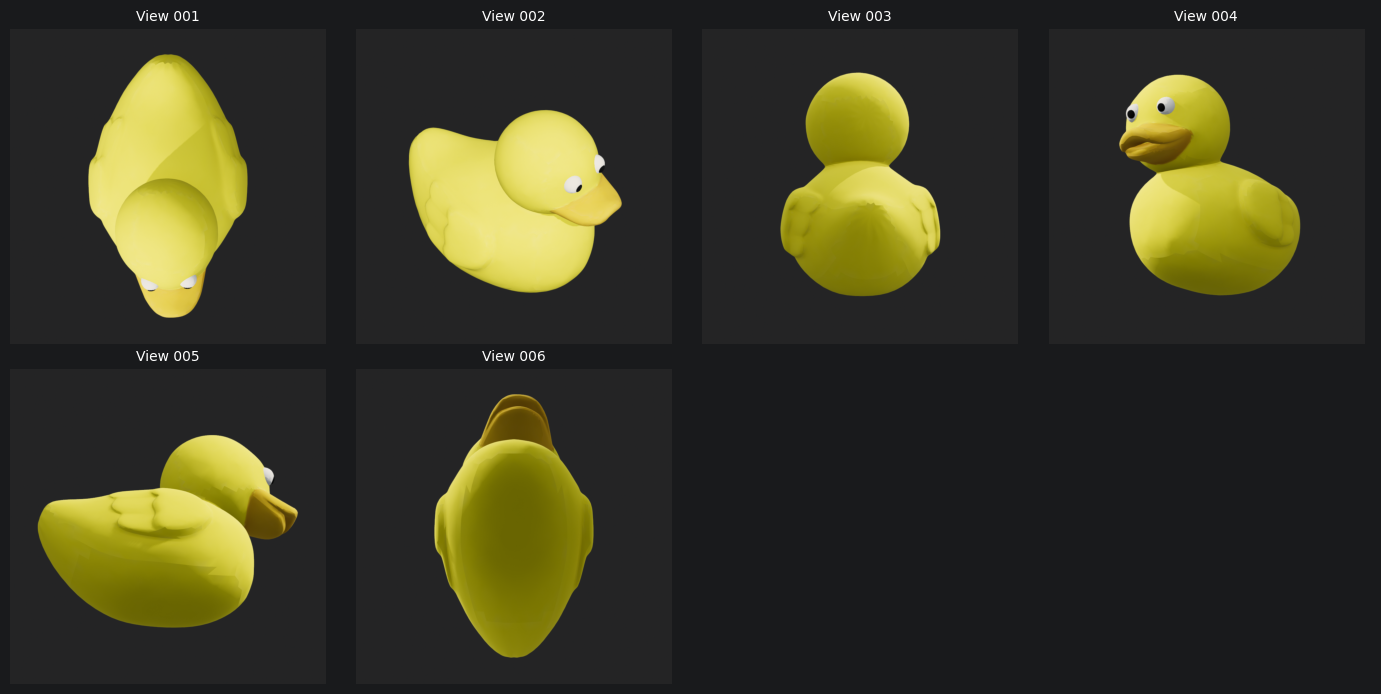

./weights are already installed
Image size (H, W, C): (1008, 1008, 3)


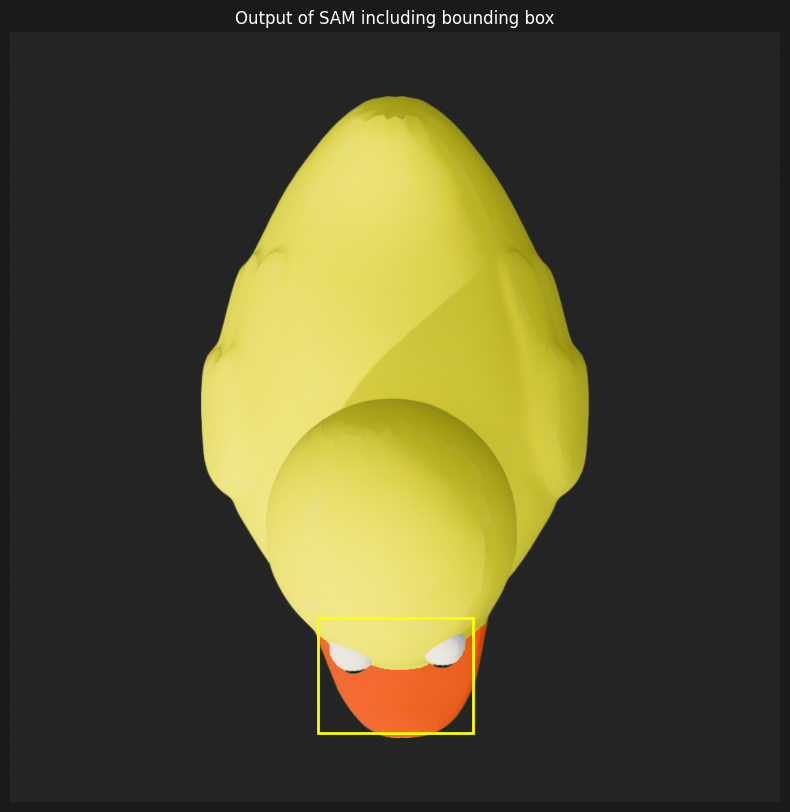

Added (mask, eye_pos) pair to valid_masks_set
[VLM] Generation truncated on rendered_views/b5c9d06f19be4c92a1708515f6655573/view_002.png; retrying with more tokens
./weights are already installed
Image size (H, W, C): (1008, 1008, 3)


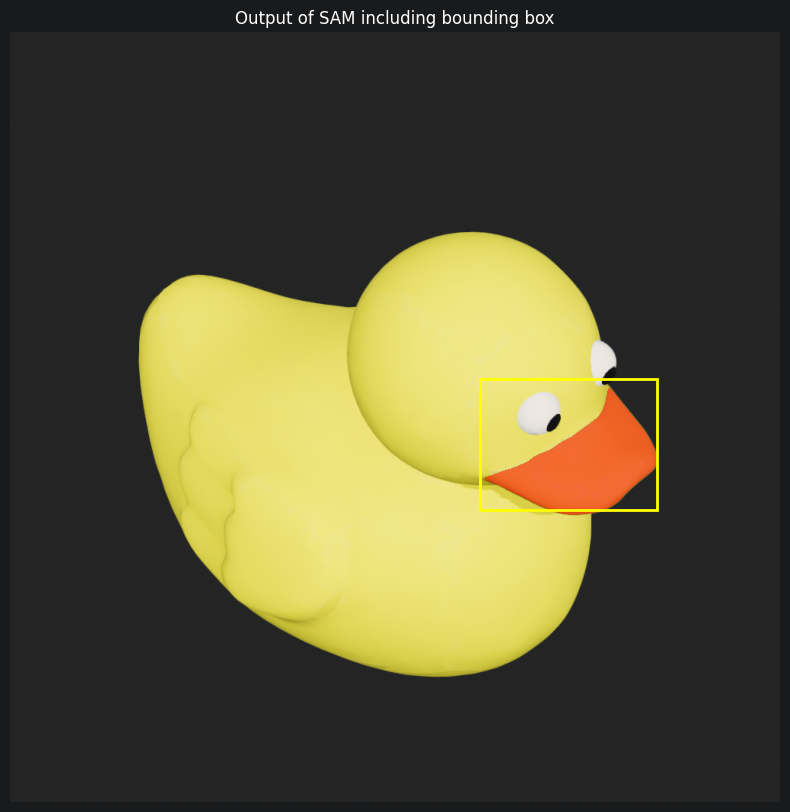

Added (mask, eye_pos) pair to valid_masks_set
[NOT FOUND] 'beak' on rendered_views/b5c9d06f19be4c92a1708515f6655573/view_003.png
[VLM] Generation truncated on rendered_views/b5c9d06f19be4c92a1708515f6655573/view_004.png; retrying with more tokens
./weights are already installed
Image size (H, W, C): (1008, 1008, 3)


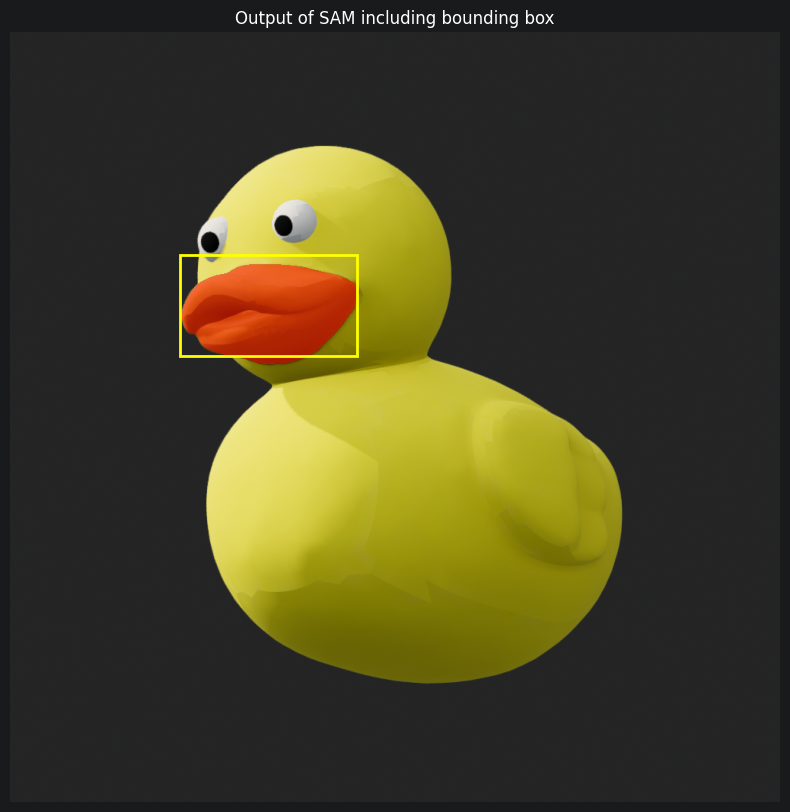

Added (mask, eye_pos) pair to valid_masks_set
[VLM] Generation truncated on rendered_views/b5c9d06f19be4c92a1708515f6655573/view_005.png; retrying with more tokens
./weights are already installed
Image size (H, W, C): (1008, 1008, 3)


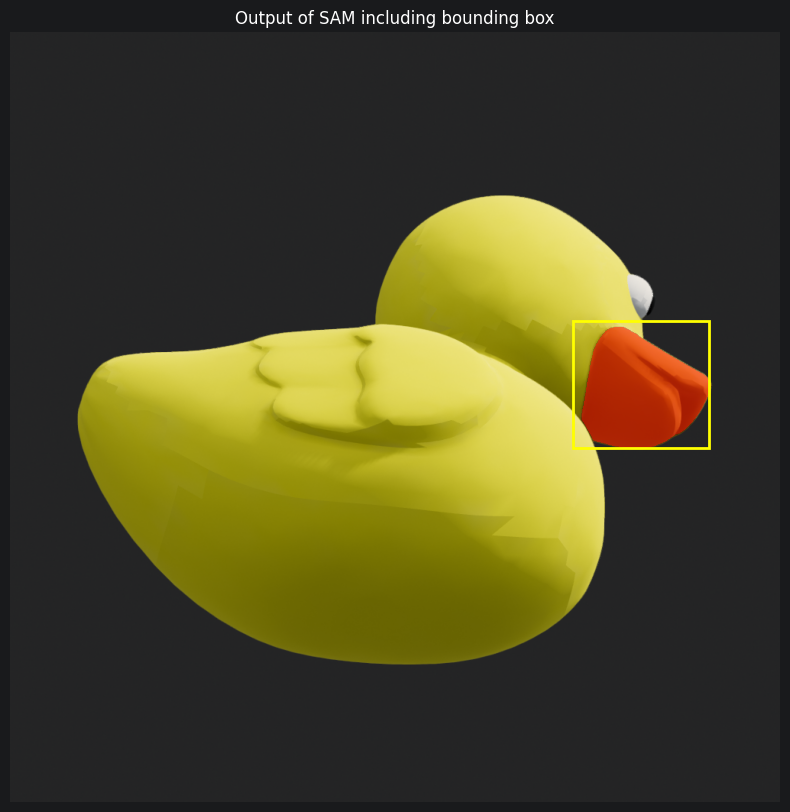

Added (mask, eye_pos) pair to valid_masks_set
./weights are already installed
Image size (H, W, C): (1008, 1008, 3)


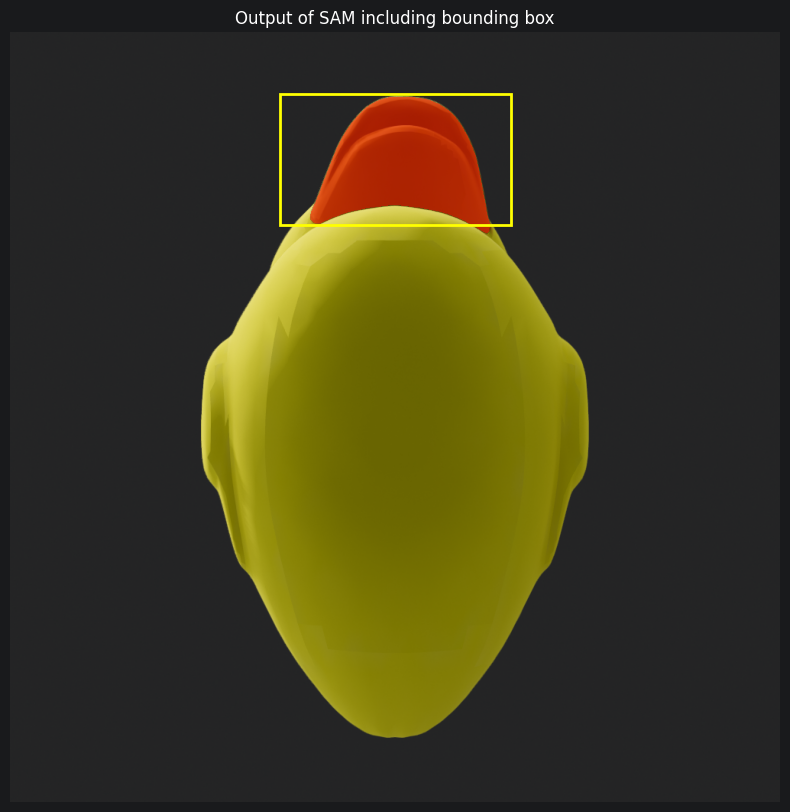

Added (mask, eye_pos) pair to valid_masks_set
Detection summary for b5c9d06f19be4c92a1708515f6655573: detected=5, not_found=1, errors=0


UID: b5c9d06f19be4c92a1708515f6655573 | Граней попало в маску: 6873


=== Processing UID: 5966083fea14434895ca6e0758843455 ===
FEngine (64 bits) created at 0x17f6f0600 (threading is enabled)
FEngine resolved backend: Metal
Selected physical device 'Apple M4'
Supported GPU families: 
  MTLGPUFamilyCommon3
  MTLGPUFamilyApple7
  MTLGPUFamilyMac2
Features:
  readWriteTextureSupport: true
Backend feature level: 3
FEngine feature level: 1


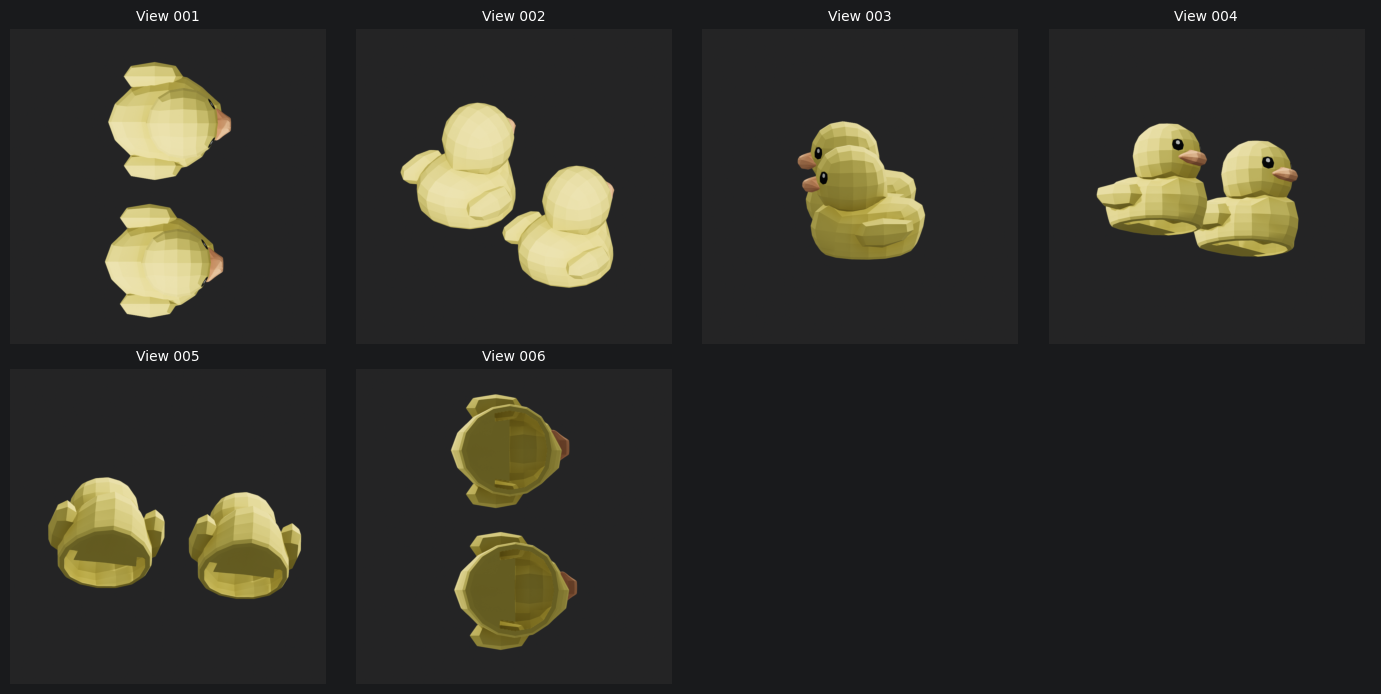

[VLM] Generation truncated on rendered_views/5966083fea14434895ca6e0758843455/view_001.png; retrying with more tokens
[VLM] Generation truncated on rendered_views/5966083fea14434895ca6e0758843455/view_001.png
[ERROR] rendered_views/5966083fea14434895ca6e0758843455/view_001.png: RuntimeError: Empty response from qwen3-vl:8b for rendered_views/5966083fea14434895ca6e0758843455/view_001.png after 2 attempts; done_reason='length'
[NOT FOUND] 'beak' on rendered_views/5966083fea14434895ca6e0758843455/view_002.png


KeyboardInterrupt: 

In [4]:
import json
import ollama
import utils
import importlib
importlib.reload(utils)
from IPython.display import display
from pathlib import Path

feature_to_detect = "beak"

# Обработка всех 3D объектов в DataLoader
for batch in objaverse_dataloader:
    uid_value = batch["uid"]
    uid = uid_value[0] if isinstance(uid_value, (list, tuple)) else uid_value
    print(f"=== Processing UID: {uid} ===")

    # Безопасное получение меша
    mesh = batch["mesh"][0] if isinstance(batch["mesh"], list) else batch["mesh"]
    output_dir = f"rendered_views/{uid}"

    # 1. Рендерим ракурсы и сразу получаем список кортежей [(eye_pos, file_path), ...]
    rendered_info = render_n_views(mesh, n_views=6, output_dir=output_dir)
    show_rendered_grid(output_dir)

    valid_masks_set = []  # Хранит пары (mask, eye_pos)
    detected_count = 0
    not_found_count = 0
    error_count = 0

    # 2. Проходим напрямую по переданным ракурсам без обхода директории
    for eye_pos, view_path in rendered_info:
        view_path_str = str(view_path)

        # A failed inference must not stop the remaining camera views or objects.
        try:
            json_output = utils.generate_bounding_box_for_image(
                "192.168.178.23", view_path_str, feature_to_detect,
                temperature=0.1, model_name="qwen3-vl:8b"
            )
            data = json.loads(json_output)
            if not data.get("is_found") or data.get("bbox_2d") is None:
                not_found_count += 1
                print(f"[NOT FOUND] '{feature_to_detect}' on {view_path_str}")
                continue

            xmin, ymin, xmax, ymax = data["bbox_2d"]
            mask = segment_image(view_path_str, xmin, ymin, xmax, ymax)
            visualize_segmentation(
                image_path=view_path_str, mask=mask,
                x1=xmin, y1=ymin, x2=xmax, y2=ymax
            )
            valid_masks_set.append((mask, eye_pos))
            detected_count += 1
            print("Added (mask, eye_pos) pair to valid_masks_set")
        except (RuntimeError, ValueError, ollama.ResponseError) as exc:
            error_count += 1
            print(f"[ERROR] {view_path_str}: {type(exc).__name__}: {exc}")
            continue

    print(f"Detection summary for {uid}: detected={detected_count}, "
          f"not_found={not_found_count}, errors={error_count}")

    # 4. Проекция на 3D модель и отображение результата


    if valid_masks_set:
        dense_mesh = mesh.subdivide()
        colored_mesh, mask_submesh = project_masks_to_3d(dense_mesh, valid_masks_set)
        display(mask_submesh.show())

        # Проверка: сколько граней действительно окрасилось в зеленый цвет
        green_faces = (colored_mesh.visual.face_colors[:, 1] == 255).sum()
        print(f"UID: {uid} | Граней попало в маску: {green_faces}")

        # 3. Отображение

        display(colored_mesh.show())
    else:
        print(f"No valid masks generated for UID: {uid}")